# Loading Dataset

In [2]:
import kagglehub
import os
import wandb

import torchvision.transforms as transforms
from torchvision.datasets import ImageFolder
from torch.utils.data import DataLoader, Subset
from tqdm import tqdm
import torch
import torch.nn.functional as F

import matplotlib.pyplot as plt 
from ignite.metrics import FID, InceptionScore

In [3]:
dataset_path = kagglehub.dataset_download("steubk/wikiart")
print(f"Dataset Path: {dataset_path}")

100%|██████████| 31.4G/31.4G [08:36<00:00, 65.2MB/s]  

Extracting files...


Dataset Path: /home/vansh/.cache/kagglehub/datasets/steubk/wikiart/versions/1


In [24]:
IMAGE_SIZE = 128

transform = transforms.Compose([
    transforms.Resize(IMAGE_SIZE),                # shorter side -> 128 (keeps aspect ratio)
    transforms.CenterCrop(IMAGE_SIZE),            # square 128x128 crop, no stretching
    transforms.RandomHorizontalFlip(),            # free augmentation, paintings still look like paintings
    transforms.ToTensor(),                        # [0, 1]
    transforms.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5]),  # [-1, 1] to match the Tanh output of G
])

dataset = ImageFolder(root=dataset_path, transform=transform)
print("Number of datapoints", len(dataset))


Number of datapoints 81444


Image shape: torch.Size([3, 128, 128])
Label: Abstract_Expressionism


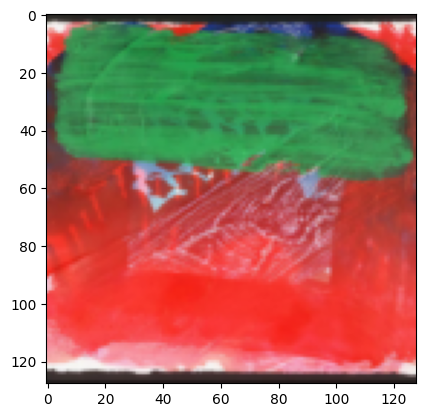

In [26]:
sample = dataset[1000]
image = sample[0]
print("Image shape:", image.shape)
plt.imshow((image.permute(1,2,0) + 1) / 2)   # undo the [-1, 1] normalization for plotting
print(f"Label: {dataset.classes[sample[1]]}")


# Model Training

In [27]:
BATCH_SIZE = 64       # 128x128 at batch 64 uses ~1.5 GB with bf16
EPOCHS = 40
LR = 0.0002
BETAS = (0.5, 0.999)
DEVICE = "cuda"
DTYPE = torch.float32
USE_AMP = True         # bf16 mixed precision: faster and uses less memory, no GradScaler needed
LATENT_DIM = 128
NUM_WORKERS = 8          # decoding the full-size WikiArt JPEGs is the bottleneck, not the GPU
EVAL_SAMPLES = 1000 
EVAL_BATCH = 50
EVAL_EVERY = 2           # epochs between FID / IS evaluations (+ checkpoint)
SAMPLE_EVERY = 10        # epochs between saving a grid of generated images
NUM_SAMPLE_IMAGES = 16   # use a square number (4x4 grid)
CHECKPOINT_DIR = "checkpoints"
RESULTS_DIR = "results"

In [28]:
torch.backends.cudnn.benchmark = True   # input size never changes, let cuDNN pick the fastest kernels

from model.GAN import GAN

gan = GAN(latent_dim=LATENT_DIM, device=DEVICE, dtype=DTYPE)

data_loader = DataLoader(dataset=dataset, batch_size=BATCH_SIZE, shuffle=True,
                         num_workers=NUM_WORKERS, pin_memory=True, drop_last=True,
                         persistent_workers=True)

# two optimizers, one per network
optimizer_G = torch.optim.Adam(gan.generator.parameters(), lr=LR, betas=BETAS)
optimizer_D = torch.optim.Adam(gan.discriminator.parameters(), lr=LR, betas=BETAS)

print("G params (M):", sum(p.numel() for p in gan.generator.parameters()) / 1e6)
print("D params (M):", sum(p.numel() for p in gan.discriminator.parameters()) / 1e6)

G params (M): 3.418195
D params (M): 7.164705


### Prepare evaluation pipeline

In [29]:
g = torch.Generator().manual_seed(0)
real_idx = torch.randperm(len(dataset), generator=g)[:EVAL_SAMPLES].tolist()
real_loader = DataLoader(Subset(dataset, real_idx), batch_size=EVAL_BATCH, shuffle=False,
                         num_workers=NUM_WORKERS)

fid_metric = FID(device=DEVICE)             # update((generated, real))
is_metric  = InceptionScore(device=DEVICE)  # update(generated)

IMAGENET_MEAN = torch.tensor([0.485, 0.456, 0.406], device=DEVICE).view(1, 3, 1, 1)
IMAGENET_STD  = torch.tensor([0.229, 0.224, 0.225], device=DEVICE).view(1, 3, 1, 1)

# same noise every time so the sample grid shows how G evolves
fixed_z = torch.randn(NUM_SAMPLE_IMAGES, LATENT_DIM, device=DEVICE, dtype=DTYPE)


def prep(x):
    """[-1,1] images (B,3,128,128) -> Inception input (B,3,299,299), ImageNet-normalized."""
    x = (x.float() + 1) / 2
    x = F.interpolate(x, size=(299, 299), mode="bilinear", align_corners=False)
    return (x - IMAGENET_MEAN) / IMAGENET_STD


@torch.no_grad()
def evaluate():
    """Generate images from z ~ N(0, I) and compute FID / Inception Score vs real images."""
    gan.generator.eval()
    fid_metric.reset()
    is_metric.reset()

    for real, _ in real_loader:
        real = real.to(device=DEVICE, dtype=DTYPE)
        with torch.autocast("cuda", dtype=torch.bfloat16, enabled=USE_AMP):
            fake = gan.generate(real.shape[0])
        fid_metric.update((prep(fake), prep(real)))
        is_metric.update(prep(fake))

    fid = float(fid_metric.compute())
    is_score = float(is_metric.compute())

    gan.generator.train()
    torch.cuda.empty_cache()
    return fid, is_score


def make_grid(samples):
    """(N, 3, H, W) with N a square number -> one (nH, nW, 3) numpy image."""
    nrow = int(len(samples) ** 0.5)
    c, h, w = samples.shape[1:]
    grid = samples.reshape(nrow, nrow, c, h, w).permute(0, 3, 1, 4, 2).reshape(nrow * h, nrow * w, c)
    return grid.clamp(0, 1).numpy()


@torch.no_grad()
def save_samples(epoch, step, out_dir):
    """Generate images from fixed_z, save the grid to out_dir and log it to wandb."""
    gan.generator.eval()
    samples = ((gan.generator(fixed_z) + 1) / 2).float().cpu()
    gan.generator.train()

    grid = make_grid(samples)
    path = os.path.join(out_dir, f"samples_epoch_{epoch:03d}.png")
    plt.imsave(path, grid)
    wandb.log({"samples": wandb.Image(path, caption=f"epoch {epoch}")}, step=step)

    plt.figure(figsize=(4, 4))
    plt.imshow(grid)
    plt.title(f"epoch {epoch}")
    plt.axis("off")
    plt.show()

### Train Model

wandb: [wandb.login()] Loaded credentials for https://api.forge.coreweave.com from /home/vansh/.netrc.
wandb: Currently logged in as: vanshraisaini (vanshraisaini-uc-san-diego) to https://api.forge.coreweave.com. Use `wandb login --relogin` to force relogin


Epoch 0: 100%|██████████| 1272/1272 [03:44<00:00,  5.67it/s, D=1.977, G=-0.691]


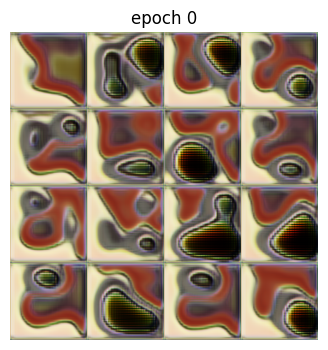

Epoch 0: FID 0.24 | IS 2.50


Epoch 2: 100%|██████████| 1272/1272 [03:51<00:00,  5.50it/s, D=1.984, G=0.181] 


Epoch 2: FID 0.20 | IS 2.51


Epoch 4: 100%|██████████| 1272/1272 [03:52<00:00,  5.47it/s, D=1.992, G=0.165]


Epoch 4: FID 0.22 | IS 2.44


Epoch 6: 100%|██████████| 1272/1272 [03:46<00:00,  5.62it/s, D=2.000, G=0.125] 


Epoch 6: FID 0.19 | IS 2.26


Epoch 8: 100%|██████████| 1272/1272 [03:45<00:00,  5.65it/s, D=2.000, G=0.318]


Epoch 8: FID 0.27 | IS 2.65


Epoch 10: 100%|██████████| 1272/1272 [03:43<00:00,  5.70it/s, D=1.992, G=0.245]


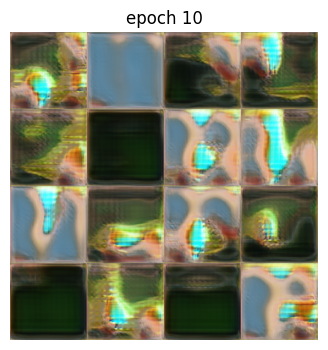

Epoch 10: FID 0.25 | IS 2.94


Epoch 12: 100%|██████████| 1272/1272 [03:41<00:00,  5.74it/s, D=2.000, G=0.428]


Epoch 12: FID 0.22 | IS 2.83


Epoch 14: 100%|██████████| 1272/1272 [03:47<00:00,  5.59it/s, D=2.000, G=0.018] 


Epoch 14: FID 0.22 | IS 2.79


Epoch 16: 100%|██████████| 1272/1272 [03:41<00:00,  5.74it/s, D=2.016, G=-0.008]


Epoch 16: FID 0.26 | IS 2.84


Epoch 18: 100%|██████████| 1272/1272 [03:41<00:00,  5.73it/s, D=2.000, G=0.320]


Epoch 18: FID 0.31 | IS 3.27


Epoch 20: 100%|██████████| 1272/1272 [03:42<00:00,  5.71it/s, D=2.000, G=0.049] 


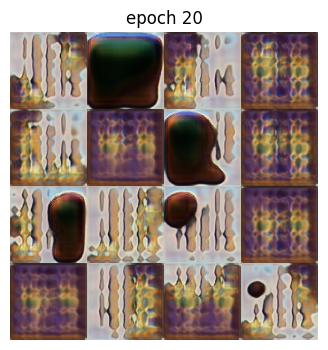

Epoch 20: FID 0.25 | IS 2.67


Epoch 22: 100%|██████████| 1272/1272 [03:46<00:00,  5.62it/s, D=2.000, G=0.153]


Epoch 22: FID 0.23 | IS 3.34


Epoch 24: 100%|██████████| 1272/1272 [03:44<00:00,  5.66it/s, D=2.000, G=0.395]


Epoch 24: FID 0.19 | IS 2.62


Epoch 26: 100%|██████████| 1272/1272 [03:44<00:00,  5.68it/s, D=2.000, G=0.527]


Epoch 26: FID 0.22 | IS 3.55


Epoch 28: 100%|██████████| 1272/1272 [03:43<00:00,  5.70it/s, D=2.000, G=0.279]


Epoch 28: FID 0.19 | IS 3.02


Epoch 30: 100%|██████████| 1272/1272 [03:42<00:00,  5.73it/s, D=2.000, G=0.660]


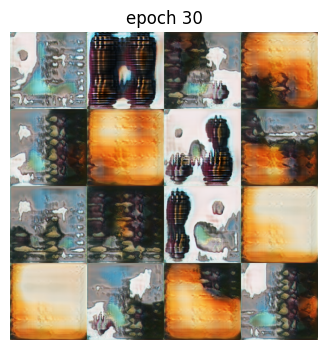

Epoch 30: FID 0.20 | IS 3.08


Epoch 32: 100%|██████████| 1272/1272 [03:53<00:00,  5.44it/s, D=2.000, G=0.391]


Epoch 32: FID 0.15 | IS 2.58


Epoch 34: 100%|██████████| 1272/1272 [03:52<00:00,  5.47it/s, D=2.000, G=0.406]


Epoch 34: FID 0.19 | IS 3.06


Epoch 36:   0%|          | 0/1272 [00:00<?, ?it/s]

In [ ]:
os.makedirs(CHECKPOINT_DIR, exist_ok=True)

run = wandb.init(project="ECE285-HW2-GAN", config=dict(
    batch_size=BATCH_SIZE, epochs=EPOCHS, lr=LR, betas=BETAS,
    latent_dim=LATENT_DIM, image_size=IMAGE_SIZE, loss="hinge", amp=USE_AMP,
))

# one sub-folder per run so different runs don't overwrite each other
run_results_dir = os.path.join(RESULTS_DIR, run.name or "offline")
os.makedirs(run_results_dir, exist_ok=True)

step = 0
for epoch in range(EPOCHS):
    pbar = tqdm(data_loader, desc=f"Epoch {epoch}")
    for real, _ in pbar:
        real = real.to(device=DEVICE, dtype=DTYPE, non_blocking=True)

        # ---- 1) update D: push real scores up, fake scores down ----
        with torch.autocast("cuda", dtype=torch.bfloat16, enabled=USE_AMP):
            fake = gan.generate(real.shape[0])
            loss_D, real_score, fake_score = gan.discriminator_loss(real, fake)
        optimizer_D.zero_grad()
        loss_D.backward()
        optimizer_D.step()

        # ---- 2) update G: fool the (just updated) D ----
        with torch.autocast("cuda", dtype=torch.bfloat16, enabled=USE_AMP):
            loss_G = gan.generator_loss(fake)
        optimizer_G.zero_grad()
        loss_G.backward()
        optimizer_G.step()

        if step % 50 == 0:
            wandb.log({
                "loss/discriminator": loss_D.item(),
                "loss/generator": loss_G.item(),
                "score/real": real_score.item(),   # should stay above fake_score but not run away
                "score/fake": fake_score.item(),
                "train/epoch": epoch,
            }, step=step)
            pbar.set_postfix(D=f"{loss_D.item():.3f}", G=f"{loss_G.item():.3f}")
        step += 1

    if epoch % SAMPLE_EVERY == 0 or epoch == EPOCHS - 1:
        save_samples(epoch, step, run_results_dir)

    if epoch % EVAL_EVERY == 0 or epoch == EPOCHS - 1:
        fid, is_score = evaluate()
        wandb.log({"eval/fid": fid, "eval/inception_score": is_score}, step=step)
        print(f"Epoch {epoch}: FID {fid:.2f} | IS {is_score:.2f}")

        torch.save({
            "generator_state_dict": gan.generator.state_dict(),
            "discriminator_state_dict": gan.discriminator.state_dict(),
            "optimizer_G_state_dict": optimizer_G.state_dict(),
            "optimizer_D_state_dict": optimizer_D.state_dict(),
            "epoch": epoch,
        }, os.path.join(CHECKPOINT_DIR, f"gan_epoch_{epoch}.pt"))

run.finish()